# Iterative Regularization: Numerical Differentiation
**Inverse Problems and Imaging (02624) — Week 8**

*Kim Knudsen with Claude, October 28, 2026*

We differentiate noisy data once more, now by **minimizing $J(x)=\|Ax-y\|^2$ iteratively**. Started from $x_0=0$, the iterates first approach the solution and then, as they start fitting the noise, move away from it. **Stopping early is the regularization** (semi-convergence). We compare two methods in three short experiments:

1. **Semi-convergence**
2. **The iterates**
3. **Noise level and stopping**

---
## 1. Setup
Numerical differentiation problem as before: $A=h\,\mathrm{tril}(\mathbf 1)$, $x^*(s)=e^{-s}(1-s)$, $N=256$. Noise is added at a prescribed **relative level** $\|d\|/\|y^*\|$. Run once.

In [9]:
# ---------- Setup: imports, numerical differentiation test problem (run once) ----------
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(2025)

N = 256
h = 1.0 / N
s = np.arange(N) * h                         # s_i = i*h,  i = 0,...,N-1

# A is the integrating matrix
A = np.tril(np.ones((N, N))) * h             # left-endpoint rule for  y(t) = int_0^t x(s) ds
x_true = np.exp(-s) * (1 - s)                # x*(s) = e^{-s}(1-s)
y_true = A @ x_true                          # y* = A x*

d0 = rng.standard_normal(N)
def noisy_y(level):
    # data with relative noise level  ||d|| / ||y*|| = level  (same noise direction for every level)
    return y_true + level * np.linalg.norm(y_true) * d0 / np.linalg.norm(d0)

print("Numerical differentiation problem ready: N =", N, ", ||A||_2 =", round(np.linalg.norm(A, 2), 4))

Numerical differentiation problem ready: N = 256 , ||A||_2 = 0.6379


---
## 2. The two methods Landweber and CGLS

**Landweber** (steepest descent):

 $\;x_{k+1} = x_k + \omega A^T(y-Ax_k),\quad x_0=0,\quad 0<\omega<2/\|A\|_2^2.$
 
 We take $\omega=1/\|A\|_2^2$.

**CGLS** (conjugate gradients on the normal equations):         ( $A^T A$ has to be positive definite )
 
$x_k=\arg\min_{x\in\mathcal K_k}\|Ax-y\|$ over the Krylov space $\mathcal K_k=\mathrm{span}\{A^Ty,\dots,(A^TA)^{k-1}A^Ty\}$, 

computed by the recursion: 
- $x_k=x_{k-1}+a_kd_{k-1}$

- $a_k=\|s_{k-1}\|^2/\|Ad_{k-1}\|^2$
- $d_k=s_k+b_kd_{k-1}$

-  $s_k=A^Tr_k$
-  $r_k=r_{k-1}-a_kAd_{k-1}$
-  $b_k=\|s_k\|^2/\|s_{k-1}\|^2$

Both functions record the relative error $\|x_k-x^*\|/\|x^*\|$ (the true solution is known) and can keep selected iterates.

In [10]:
def landweber(A, y, omega, kmax, x_true, keep=()):
    x = np.zeros(A.shape[1]); errs = np.empty(kmax + 1); errs[0] = 1.0; iterates = {}
    for k in range(1, kmax + 1):
        x = x + omega * (A.T @ (y - A @ x))
        errs[k] = np.linalg.norm(x - x_true) / np.linalg.norm(x_true)
        if k in keep: iterates[k] = x.copy()
    return errs, iterates

def cgls(A, y, kmax, x_true, keep=()):
    x = np.zeros(A.shape[1]); r = y.copy(); sk = A.T @ r; d = sk.copy(); ss = sk @ sk
    errs = np.empty(kmax + 1); errs[0] = 1.0; iterates = {}
    for k in range(1, kmax + 1):
        Ad = A @ d
        a = ss / (Ad @ Ad)
        x = x + a * d; r = r - a * Ad; sk = A.T @ r
        ss_new = sk @ sk
        d = sk + (ss_new / ss) * d; ss = ss_new
        errs[k] = np.linalg.norm(x - x_true) / np.linalg.norm(x_true)
        if k in keep: iterates[k] = x.copy()
    return errs, iterates

---
## 3. Experiments

### 3.1 Semi-convergence
Data with **1% noise**. Both error histories (note the log–log axes) go down, reach a minimum, and then rise again as noise is amplified. CGLS does the same job in far fewer iterations.

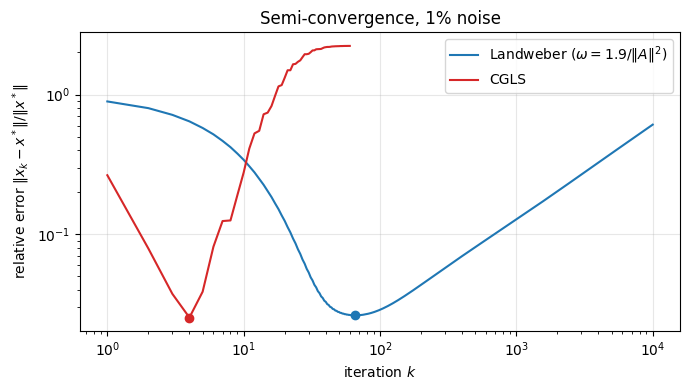

Landweber: best k = 65,  error = 0.0262
CGLS:      best k = 4,  error = 0.0253


In [11]:
noise_level = 0.01
y_obs = noisy_y(noise_level)
K_lw, K_cg = 10000, 60
c = 1.9
omega = c / np.linalg.norm(A, 2)**2
err_lw, _ = landweber(A, y_obs, omega, K_lw, x_true)
err_cg, _ = cgls(A, y_obs, K_cg, x_true)
k_lw, k_cg = err_lw.argmin(), err_cg.argmin()

fig, ax = plt.subplots()
ax.loglog(np.arange(1, K_lw + 1), err_lw[1:], "C0", label=rf"Landweber ($\omega={c:g}/\|A\|^2$)")
ax.loglog(np.arange(1, K_cg + 1), err_cg[1:], "C3", label="CGLS")
ax.plot([k_lw], [err_lw[k_lw]], "C0o"); ax.plot([k_cg], [err_cg[k_cg]], "C3o")
ax.set_xlabel("iteration $k$"); ax.set_ylabel(r"relative error $\|x_k-x^*\|/\|x^*\|$")
ax.set_title("Semi-convergence, 1% noise"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Landweber: best k = {k_lw},  error = {err_lw[k_lw]:.4f}")
print(f"CGLS:      best k = {k_cg},  error = {err_cg[k_cg]:.4f}")

### 3.2 What the iterates look like
CGLS iterates for the same data: **too early** (smooth, underfitted), **best**, and **too late** (the noise has taken over). Stopping at the right $k$ plays the role of $\alpha$ in Tikhonov or the truncation level in TSVD.

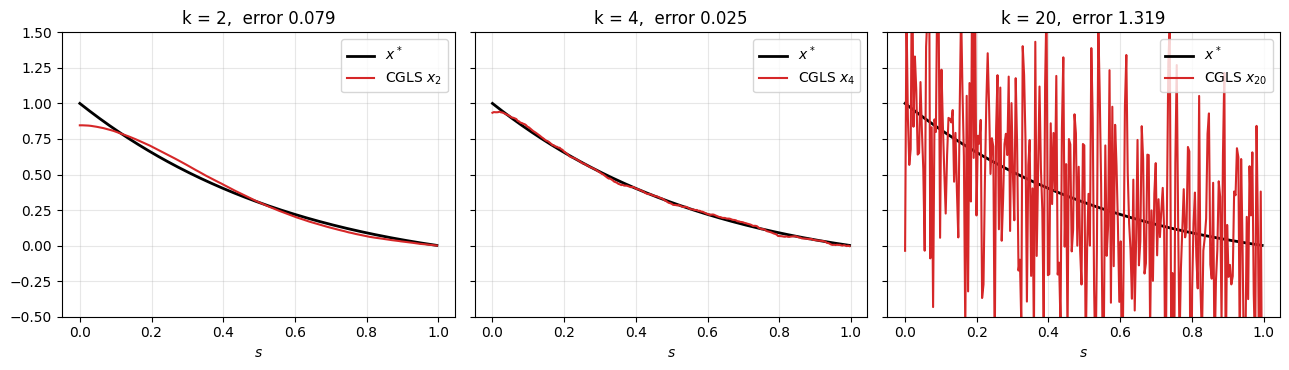

In [12]:
ks = [2, k_cg, 20]
_, its = cgls(A, y_obs, max(ks), x_true, keep=ks)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a_, k in zip(ax, ks):
    a_.plot(s, x_true, "k", lw=2, label="$x^*$")
    a_.plot(s, its[k], "C3", lw=1.5, label=f"CGLS $x_{{{k}}}$")
    a_.set_title(f"k = {k},  error {err_cg[k]:.3f}"); a_.set_xlabel("$s$"); a_.legend()
ax[0].set_ylim(-0.5, 1.5)
plt.tight_layout(); plt.show()

### 3.3 Stopping index depends on the noise
Same experiment for three noise levels. Less noise means we can iterate longer before noise takes over, so the best $k$ grows.

In [14]:
print(f"{'noise':>6} | {'Landweber: best k':>18} {'error':>7} | {'CGLS: best k':>13} {'error':>7}")
for level in [0.05, 0.01, 0.001]:
    y_l = noisy_y(level)
    eL, _ = landweber(A, y_l, omega, 20000, x_true)
    eC, _ = cgls(A, y_l, K_cg, x_true)
    print(f"{level:>6.1%} | {eL.argmin():>18d} {eL.min():>7.4f} | {eC.argmin():>13d} {eC.min():>7.4f}")

 noise |  Landweber: best k   error |  CGLS: best k   error
  5.0% |                 35  0.0646 |             3  0.0543
  1.0% |                 65  0.0262 |             4  0.0253
  0.1% |                302  0.0087 |             7  0.0088


---
## Take-aways
* **Stopping is regularization**
* **Landweber** is simple but slow
* **CGLS** reaches a comparable best error in a handful of iterations and meets the noise sooner